# 01 · Keşifsel Veri Analizi ve İstatistiksel Testler

**Amaç:** Modellemeye geçmeden önce veriyi tanımak: veri kalitesi, sınıf dengesizliği ve
hangi değişkenlerin sahtekârlıkla ilişkili olduğu. İlişkiler yalnızca grafikle değil,
uygun istatistiksel testler ve **etki büyüklükleriyle** değerlendirilir.

**Veri:** 1994–1996 yıllarına ait 15.420 araç sigortası hasar talebi (`fraud_oracle`).
Hedef değişken `FraudFound_P` (1 = sahtekârlık tespit edildi).

> **Önemli not:** Etiket "sahtekârlık *tespit edildi*" anlamına gelir. Yakalanmamış
> sahtekârlıklar veride "meşru" görünür. Bu yüzden bulgular "tespit edilen sahtekârlık"
> için geçerlidir; bu, tüm sahtekârlık modellerinin ortak sınırlılığıdır.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, data, plotting, stats as st

plotting.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Veriyi yükleme

In [2]:
raw = data.load_raw()
print(f"Rows: {raw.shape[0]:,}  Columns: {raw.shape[1]}")
raw.head()

Rows: 15,420  Columns: 33


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


In [3]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "n_missing": raw.isna().sum(),
    "example": raw.iloc[0].astype(str),
})
overview

,dtype,n_unique,n_missing,example
Month,str,12,0,Dec
WeekOfMonth,int64,5,0,5
DayOfWeek,str,7,0,Wednesday
Make,str,19,0,Honda
AccidentArea,str,2,0,Urban
DayOfWeekClaimed,str,8,0,Tuesday
MonthClaimed,str,13,0,Jan
WeekOfMonthClaimed,int64,5,0,1
Sex,str,2,0,Female
MaritalStatus,str,4,0,Single


Değişkenlerin neredeyse tamamı **kategorik** (çoğu aralıklara bölünmüş). Bu, analiz
yöntemini belirler: ilişkiler için ki-kare testi ve Cramér's V, sıralı değişkenler için
eğilim testi kullanılacak.

## 2. Veri kalitesi

Veride resmî olarak hiç `NaN` yok; ancak "eksik veri yok" demek için gizli kodlara da
bakmak gerekir.

In [4]:
print("Explicit missing values :", int(raw.isna().sum().sum()))
print("Duplicated rows         :", int(raw.duplicated().sum()))
print("Age == 0                :", int((raw["Age"] == 0).sum()))
print("Claim date coded '0'    :", int((raw["DayOfWeekClaimed"] == "0").sum()))
print("PolicyNumber is row id  :", bool((raw["PolicyNumber"].to_numpy() == np.arange(1, len(raw) + 1)).all()))

Explicit missing values : 0
Duplicated rows         : 0
Age == 0                : 320
Claim date coded '0'    : 1
PolicyNumber is row id  : True


In [5]:
# Age == 0 is not a real age: every such row sits in the youngest age band.
raw.loc[raw["Age"] == 0, "AgeOfPolicyHolder"].value_counts()

AgeOfPolicyHolder
16 to 17    320
Name: count, dtype: int64

In [6]:
# Age vs. the binned AgeOfPolicyHolder: the bands do not match their labels.
(raw[raw["Age"] > 0]
 .groupby("AgeOfPolicyHolder")["Age"].agg(["min", "max", "size"])
 .reindex(config.ORDINAL_FEATURES["AgeOfPolicyHolder"]))

,min,max,size
AgeOfPolicyHolder,,,
16 to 17,NaN,NaN,NaN
18 to 20,16.0000,17.0000,15.0000
21 to 25,18.0000,20.0000,108.0000
26 to 30,21.0000,25.0000,613.0000
31 to 35,26.0000,35.0000,"5,593.0000"
36 to 40,36.0000,45.0000,"4,043.0000"
41 to 50,46.0000,55.0000,"2,828.0000"
51 to 65,56.0000,65.0000,"1,392.0000"
over 65,66.0000,80.0000,508.0000


In [7]:
# PolicyType is a combination of VehicleCategory and BasePolicy (no extra information).
raw.groupby(["PolicyType", "VehicleCategory", "BasePolicy"]).size().rename("n").reset_index()

,PolicyType,VehicleCategory,BasePolicy,n
0,Sedan - All Perils,Sedan,All Perils,4087
1,Sedan - Collision,Sedan,Collision,5584
2,Sedan - Liability,Sport,Liability,4987
3,Sport - All Perils,Sport,All Perils,22
4,Sport - Collision,Sport,Collision,348
5,Sport - Liability,Sport,Liability,1
6,Utility - All Perils,Utility,All Perils,340
7,Utility - Collision,Utility,Collision,30
8,Utility - Liability,Utility,Liability,21


**Veri kalitesi bulguları ve alınan kararlar**

| Bulgu | Karar |
|---|---|
| `Age = 0` olan 320 kayıt var; hepsi "16 to 17" yaş bandında | Gizli eksik değer. `Age` EDA'da 0'lar hariç kullanılır, modelde yerine eksiksiz olan `AgeOfPolicyHolder` kullanılır |
| `Age` ile `AgeOfPolicyHolder` etiketleri tutarsız (ör. "31 to 35" bandında 26–35 yaş var) | Bant **sıralaması** güvenilir, etiketler değil; değişken sıralı (ordinal) olarak kodlanır |
| 1 kayıtta hasar bildirim günü/ayı "0" | Kayıt çıkarılır (15.419 kayıt kalır) |
| `PolicyNumber` satır numarasıdır | Modelden çıkarılır (bilgi taşımaz, sızıntı riski) |
| `PolicyType` = `VehicleCategory` × `BasePolicy` | Modelden çıkarılır (tam bağımlılık). Ayrıca "Sedan - Liability" poliçeleri `VehicleCategory = Sport` olarak kodlanmış; kaynak verideki bir tutarsızlık |
| `Year` | Gelecekteki hasarlarda genellenemez; modele girmez, zaman dışı doğrulamada kullanılır |

In [8]:
df = data.clean(raw)
print(f"Rows after cleaning: {len(df):,}")
print("New feature ClaimLagMonths (months between accident and claim, capped at 3):")
df["ClaimLagMonths"].value_counts().sort_index()

Rows after cleaning: 15,419
New feature ClaimLagMonths (months between accident and claim, capped at 3):


ClaimLagMonths
0    11442
1     3211
2      390
3      376
Name: count, dtype: int64

## 3. Sınıf dengesizliği

In [9]:
counts = df[config.TARGET].value_counts().sort_index()
fraud_rate = df[config.TARGET].mean()
print(counts.rename({0: "legitimate", 1: "fraud"}))
print(f"Fraud rate: {fraud_rate:.2%}  ->  1 fraud per {counts[0] / counts[1]:.1f} legitimate claims")

FraudFound_P
legitimate    14496
fraud           923
Name: count, dtype: int64
Fraud rate: 5.99%  ->  1 fraud per 15.7 legitimate claims


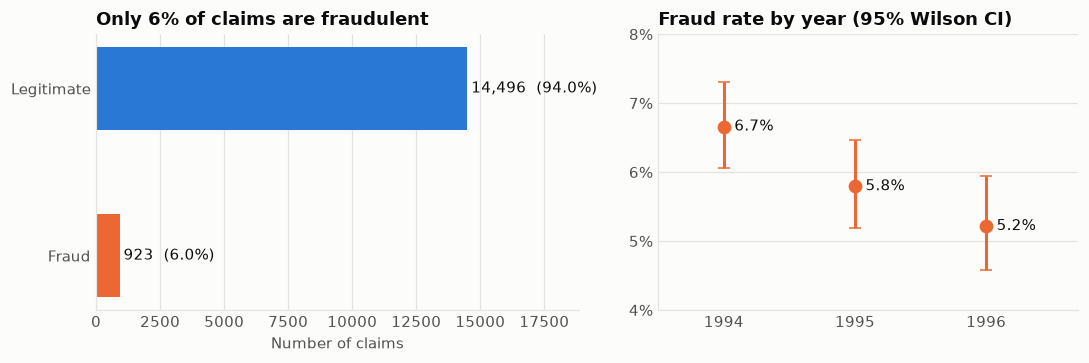

In [10]:
by_year = st.rate_table(df, "Year", config.TARGET)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1.15, 1]})

ax = axes[0]
bars = ax.barh(["Fraud", "Legitimate"], [counts[1], counts[0]],
               color=[plotting.COLOR_FRAUD, plotting.COLOR_LEGIT], height=0.5)
for bar, n in zip(bars, [counts[1], counts[0]]):
    ax.text(bar.get_width() + 150, bar.get_y() + bar.get_height() / 2,
            f"{n:,}  ({n / len(df):.1%})", va="center", color=plotting.INK)
ax.set_xlim(0, counts[0] * 1.3)
ax.set_xlabel("Number of claims")
ax.set_title("Only 6% of claims are fraudulent")
ax.grid(axis="y", visible=False)

ax = axes[1]
x = np.arange(len(by_year))
ax.errorbar(x, by_year["rate"],
            yerr=[by_year["rate"] - by_year["ci_low"], by_year["ci_high"] - by_year["rate"]],
            fmt="o", color=plotting.COLOR_FRAUD, markersize=8, capsize=4, linewidth=2)
for xi, r in zip(x, by_year["rate"]):
    ax.text(xi + 0.08, r, f"{r:.1%}", va="center", color=plotting.INK)
ax.set_xticks(x, by_year.index.astype(str))
ax.set_xlim(-0.5, len(x) - 0.3)
ax.set_ylim(0.04, 0.08)
ax.set_yticks([0.04, 0.05, 0.06, 0.07, 0.08])
plotting.pct_axis(ax)
ax.set_title("Fraud rate by year (95% Wilson CI)")
ax.grid(axis="x", visible=False)

fig.tight_layout()
plotting.save_fig(fig, "01_class_balance")
plt.show()

Sahtekârlık oranı yaklaşık **%6**. Bunun iki sonucu var:

1. **Accuracy yanıltıcıdır.** Her talebe "meşru" diyen bir model %94 doğruluk elde eder
   ama tek bir sahtekârlık yakalamaz. Bu yüzden projede precision, recall, F1 ve PR-AUC
   kullanılır.
2. Oran yıllar içinde düşüyor (sağdaki grafik). Bu, zamanla değişen bir süreç olduğunu
   gösterir; modelleme defterinde ayrıca **zaman dışı doğrulama** yapılır.

## 4. Hangi değişkenler sahtekârlıkla ilişkili? (Ki-kare + Cramér's V)

Her değişken için **H₀: değişken ile sahtekârlık bağımsızdır** hipotezi ki-kare bağımsızlık
testiyle sınanır. Üç noktaya dikkat edilir:

- **Çoklu test:** 31 hipotez aynı anda test edildiği için p-değerleri
  Benjamini–Hochberg (FDR) yöntemiyle düzeltilir.
- **Etki büyüklüğü:** n ≈ 15.000 olduğunda çok küçük farklar bile "anlamlı" çıkar.
  Bu yüzden asıl sıralama, yanlılığı düzeltilmiş **Cramér's V** ile yapılır.
- **Varsayım kontrolü:** Beklenen frekansı 5'in altında hücre olan tablolar işaretlenir.

In [11]:
screen_features = config.FEATURES + ["PolicyType", "Year"]
screen = st.chi_square_screen(df, screen_features, config.TARGET)
screen["weak_approximation"] = screen["min_expected"] < 5
screen

,feature,levels,chi2,dof,p_value,cramers_v,min_expected,p_adj_bh,significant,weak_approximation
0,PolicyType,9,437.4914,8,0.0000,0.1669,0.0599,0.0000,True,True
1,BasePolicy,3,402.9472,2,0.0000,0.1613,266.2627,0.0000,True,False
2,VehicleCategory,3,290.9809,2,0.0000,0.1369,23.4057,0.0000,True,False
3,Fault,2,266.2282,1,0.0000,0.1312,250.8185,0.0000,True,False
4,AddressChange_Claim,5,104.7227,4,0.0000,0.0808,0.2394,0.0000,True,True
5,Deductible,4,72.4063,3,0.0000,0.0671,0.4789,0.0000,True,True
6,VehiclePrice,6,67.8361,5,0.0000,0.0638,5.2079,0.0000,True,False
7,PastNumberOfClaims,4,53.5418,3,0.0000,0.0573,120.3210,0.0000,True,False
8,Make,19,59.8153,18,0.0000,0.0521,0.0599,0.0000,True,True
9,MonthClaimed,12,42.2005,11,0.0000,0.0450,67.4037,0.0000,True,False


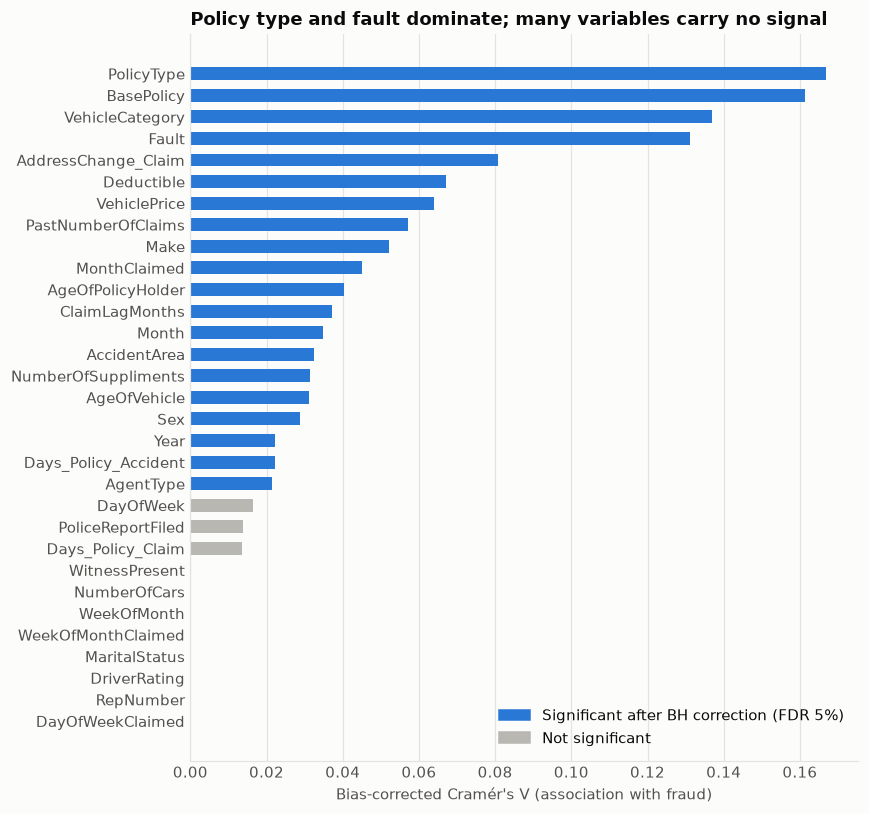

In [12]:
grey = "#b8b7b2"
plot_df = screen.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(plot_df["feature"], plot_df["cramers_v"], height=0.6,
        color=[plotting.BLUE if s else grey for s in plot_df["significant"]])
ax.set_xlabel("Bias-corrected Cramér's V (association with fraud)")
ax.set_title("Policy type and fault dominate; many variables carry no signal")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=plotting.BLUE),
           plt.Rectangle((0, 0), 1, 1, color=grey)]
ax.legend(handles, ["Significant after BH correction (FDR 5%)", "Not significant"],
          loc="lower right")
fig.tight_layout()
plotting.save_fig(fig, "02_cramers_v")
plt.show()

In [13]:
n_sig = int(screen["significant"].sum())
print(f"{n_sig} of {len(screen)} variables are significant after BH correction.")
print("Largest effect sizes:")
print(screen.loc[:5, ["feature", "cramers_v", "p_adj_bh"]].to_string(index=False))
print("\nSignificant but with a weak chi-square approximation (expected count < 5):")
print(screen.loc[screen["significant"] & screen["weak_approximation"], "feature"].tolist())

20 of 31 variables are significant after BH correction.
Largest effect sizes:
            feature  cramers_v  p_adj_bh
         PolicyType     0.1669    0.0000
         BasePolicy     0.1613    0.0000
    VehicleCategory     0.1369    0.0000
              Fault     0.1312    0.0000
AddressChange_Claim     0.0808    0.0000
         Deductible     0.0671    0.0000

Significant but with a weak chi-square approximation (expected count < 5):
['PolicyType', 'AddressChange_Claim', 'Deductible', 'Make', 'AgeOfPolicyHolder', 'AgeOfVehicle', 'Days_Policy_Accident']


**Yorum**

- En güçlü ilişkiler poliçe türü (`BasePolicy`, `PolicyType`), araç kategorisi ve kusur
  (`Fault`) ile. Yine de en yüksek Cramér's V ≈ 0,17: Cohen'in ölçütlerine göre
  **zayıf–orta** düzeyde. Tek başına hiçbir değişken sahtekârlığı açıklamıyor;
  bu da çok değişkenli bir modeli gerekli kılıyor.
- Değişkenlerin çoğu istatistiksel olarak anlamlı ama etkileri çok küçük
  (V < 0,05). "Anlamlı" ile "önemli" aynı şey değil.
- `WitnessPresent`, `PoliceReportFiled`, `DriverRating`, `RepNumber`, `MaritalStatus`
  gibi değişkenlerde ilişki bulunamadı.
- Bazı tablolarda çok seyrek düzeyler var (ör. `AddressChange_Claim = under 6 months`
  yalnızca 4 kayıt). Bu tablolarda ki-kare yaklaşımı zayıftır; sonuçlar aşağıda güven
  aralıklarıyla birlikte okunmalıdır.

## 5. Düzey bazında sahtekârlık oranları

En güçlü altı değişken için her düzeyin sahtekârlık oranı ve %95 Wilson güven aralığı.
Kesikli çizgi genel ortalamadır (%6).

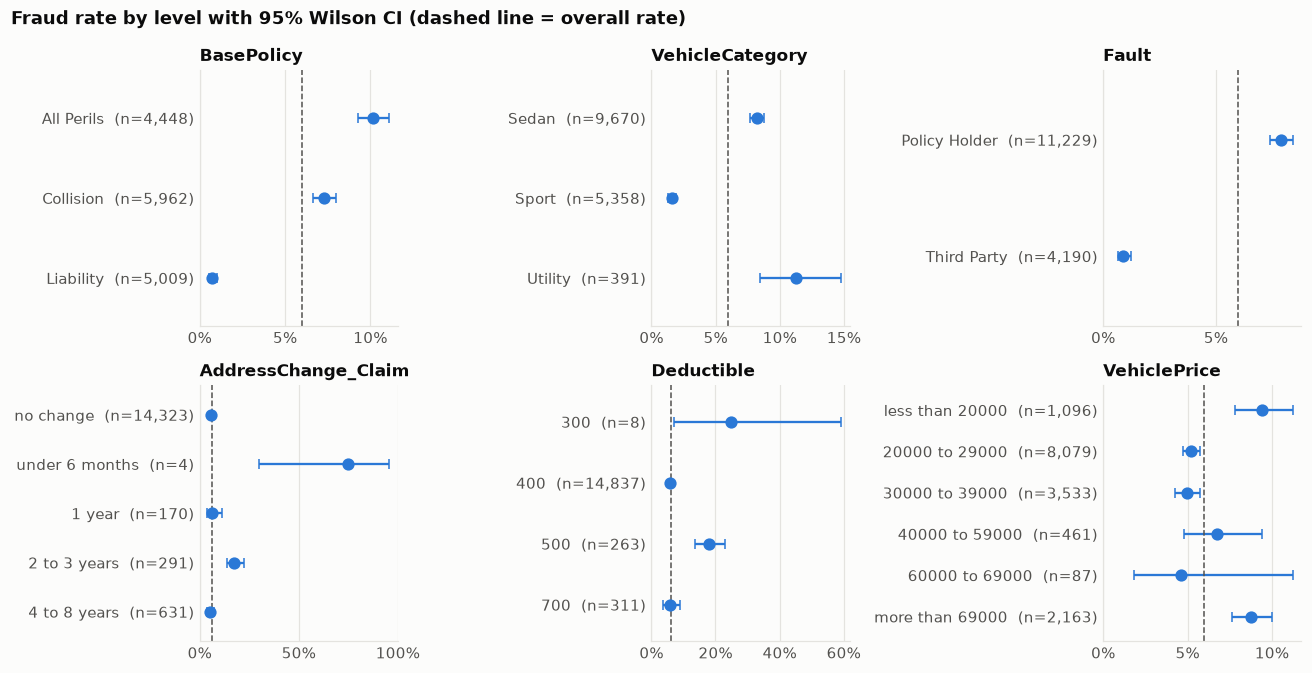

In [14]:
top6 = [f for f in screen["feature"] if f != "PolicyType"][:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for ax, feature in zip(axes.ravel(), top6):
    table = st.rate_table(df, feature, config.TARGET, config.ORDINAL_FEATURES.get(feature))
    y = np.arange(len(table))[::-1]
    ax.errorbar(table["rate"], y,
                xerr=[table["rate"] - table["ci_low"], table["ci_high"] - table["rate"]],
                fmt="o", color=plotting.BLUE, markersize=7, capsize=3, linewidth=1.5)
    ax.axvline(fraud_rate, color=plotting.INK_MUTED, linestyle="--", linewidth=1)
    ax.set_yticks(y, [f"{lvl}  (n={n:,})" for lvl, n in zip(table.index, table["n"])])
    ax.set_ylim(-0.6, len(table) - 0.4)
    ax.set_xlim(left=0)
    ax.xaxis.set_major_locator(plt.MaxNLocator(nbins=4, steps=[1, 2, 5, 10]))
    plotting.pct_axis(ax, "x")
    ax.set_title(feature, fontsize=11)
    ax.grid(axis="y", visible=False)
fig.suptitle("Fraud rate by level with 95% Wilson CI (dashed line = overall rate)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plotting.save_fig(fig, "03_fraud_rate_by_level")
plt.show()

In [15]:
for feature in ["Fault", "BasePolicy", "VehicleCategory", "AddressChange_Claim", "Deductible"]:
    print(st.rate_table(df, feature, config.TARGET, config.ORDINAL_FEATURES.get(feature)), "\n")

                   n  frauds   rate  ci_low  ci_high
Fault                                               
Policy Holder  11229     886 0.0789  0.0741   0.0840
Third Party     4190      37 0.0088  0.0064   0.0121 

               n  frauds   rate  ci_low  ci_high
BasePolicy                                      
All Perils  4448     452 0.1016  0.0931   0.1108
Collision   5962     435 0.0730  0.0666   0.0798
Liability   5009      36 0.0072  0.0052   0.0099 

                    n  frauds   rate  ci_low  ci_high
VehicleCategory                                      
Sedan            9670     795 0.0822  0.0769   0.0879
Sport            5358      84 0.0157  0.0127   0.0194
Utility           391      44 0.1125  0.0849   0.1477 

                         n  frauds   rate  ci_low  ci_high
AddressChange_Claim                                       
no change            14323     825 0.0576  0.0539   0.0615
under 6 months           4       3 0.7500  0.3006   0.9544
1 year                 170     

**Öne çıkanlar**

- **Kusur:** Poliçe sahibinin kusurlu olduğu taleplerde oran %7,9; üçüncü tarafın
  kusurlu olduğu taleplerde %0,9. Yaklaşık 9 kat fark.
- **Poliçe türü:** "All Perils" %10,2 ve "Collision" %7,3 iken "Liability" yalnızca %0,7.
  Sorumluluk (liability) poliçesinde ödeme üçüncü kişiye gider; poliçe sahibinin
  doğrudan kazancı yoktur. Bu, alan bilgisiyle tutarlı bir bulgudur.
- **Adres değişikliği:** Hasardan 2–3 yıl önce adres değiştirenlerde oran %17,5.
  "under 6 months" düzeyi %75 görünüyor ama yalnızca 4 kayda dayanıyor; güven aralığı
  %30–%95. Bu düzey hakkında güvenilir bir şey söylenemez.
- **Muafiyet (deductible):** 500 düzeyinde oran %17,9; 400 ve 700 düzeylerinde %5,8.
  İlişki doğrusal değil; bu yüzden lojistik regresyonda kategorik olarak kodlanır.

## 6. Sıralı değişkenlerde eğilim (Cochran–Armitage)

Ki-kare testi düzeylerin sırasını kullanmaz. Sıralı değişkenlerde "düzey arttıkça oran
sistematik olarak artıyor/azalıyor mu?" sorusu için Cochran–Armitage eğilim testi daha
güçlüdür.

In [16]:
trend_rows = []
for feature in ["PastNumberOfClaims", "AgeOfVehicle", "AgeOfPolicyHolder", "NumberOfSuppliments",
                "VehiclePrice", "ClaimLagMonths", "DriverRating", "Year"]:
    order = config.ORDINAL_FEATURES.get(feature, sorted(df[feature].unique()))
    table = pd.crosstab(df[feature], df[config.TARGET]).reindex(order)
    z, p = st.cochran_armitage_trend(table)
    rates = (table[1] / table.sum(axis=1)).round(3).tolist()
    trend_rows.append({"feature": feature, "z": z, "p_value": p,
                       "direction": "increasing" if z > 0 else "decreasing",
                       "rate_by_level": rates})
trend = pd.DataFrame(trend_rows).sort_values("p_value").reset_index(drop=True)
pd.set_option("display.max_colwidth", 80)
trend

,feature,z,p_value,direction,rate_by_level
0,PastNumberOfClaims,-7.2146,0.0000,decreasing,"[0.078, 0.062, 0.054, 0.034]"
1,AgeOfVehicle,-4.1365,0.0000,decreasing,"[0.086, 0.041, 0.086, 0.092, 0.07, 0.066, 0.056, 0.052]"
2,NumberOfSuppliments,-3.9931,0.0001,decreasing,"[0.067, 0.064, 0.048, 0.05]"
3,AgeOfPolicyHolder,-3.9780,0.0001,decreasing,"[0.097, 0.133, 0.148, 0.054, 0.064, 0.059, 0.051, 0.05, 0.059]"
4,VehiclePrice,3.9383,0.0001,increasing,"[0.094, 0.052, 0.05, 0.067, 0.046, 0.087]"
5,ClaimLagMonths,3.9123,0.0001,increasing,"[0.055, 0.07, 0.105, 0.066]"
6,Year,-3.0768,0.0021,decreasing,"[0.067, 0.058, 0.052]"
7,DriverRating,0.9014,0.3674,increasing,"[0.059, 0.056, 0.062, 0.062]"


- **Geçmiş hasar sayısı arttıkça sahtekârlık oranı düşüyor** (hiç hasarı olmayanlarda
  %7,8; 4'ten fazla olanlarda %3,4). İlk bakışta sezgiye aykırı; aşağıda bunun bir
  **karıştırıcı değişken** etkisi olup olmadığı kontrol ediliyor.
- Araç yaşı ve poliçe sahibinin yaşı arttıkça oran düşüyor.
- `DriverRating` için eğilim yok (p = 0,37).
- `VehiclePrice` ve `ClaimLagMonths` testte anlamlı görünse de oranlar tekdüze artmıyor
  (U biçimi / tek tepe). Eğilim testi doğrusal eğilim varsayar; bu iki değişkende
  sonuç dikkatle yorumlanmalı.

### 6.1 Karıştırıcı etki kontrolü: geçmiş hasar sayısı

Geçmiş hasar sayısı ile sahtekârlık arasındaki ilişki, poliçe türü sabit tutulduğunda
da sürüyor mu?

In [17]:
order = config.ORDINAL_FEATURES["PastNumberOfClaims"]
mix = pd.crosstab(df["PastNumberOfClaims"], df["BasePolicy"], normalize="index").reindex(order)
within = df.pivot_table(index="PastNumberOfClaims", columns="BasePolicy",
                        values=config.TARGET, aggfunc="mean").reindex(order)
print("Policy mix by past number of claims (row shares):")
print(mix.round(3), "\n")
print("Fraud rate by past number of claims WITHIN each base policy:")
print(within.round(3), "\n")
for policy in within.columns:
    sub = df[df["BasePolicy"] == policy]
    z, p = st.cochran_armitage_trend(pd.crosstab(sub["PastNumberOfClaims"], sub[config.TARGET]).reindex(order))
    print(f"Trend test within {policy:<10}: z = {z:+.2f}, p = {p:.3f}")

Policy mix by past number of claims (row shares):
BasePolicy          All Perils  Collision  Liability
PastNumberOfClaims                                  
none                    0.4190     0.4440     0.1370
1                       0.3410     0.4350     0.2240
2 to 4                  0.2110     0.3700     0.4190
more than 4             0.1230     0.2230     0.6540 

Fraud rate by past number of claims WITHIN each base policy:
BasePolicy          All Perils  Collision  Liability
PastNumberOfClaims                                  
none                    0.1000     0.0770     0.0120
1                       0.1030     0.0600     0.0040
2 to 4                  0.1050     0.0760     0.0070
more than 4             0.0890     0.0830     0.0070 

Trend test within All Perils: z = -0.00, p = 0.999
Trend test within Collision : z = +0.39, p = 0.695
Trend test within Liability : z = -0.56, p = 0.579


**Simpson paradoksuna benzer bir durum.** 4'ten fazla geçmiş hasarı olanların %65'i
sorumluluk (liability) poliçesi sahibi; bu poliçe türünde sahtekârlık oranı zaten çok
düşük. Poliçe türü sabit tutulduğunda eğilim kayboluyor (üç alt grupta da p > 0,05).
Yani "geçmiş hasarı çok olan daha az sahtekârlık yapıyor" çıkarımı yanlış olurdu;
görünen ilişki **poliçe karışımından** kaynaklanıyor.

### 6.2 İki sinyal mi, tek sinyal mi? Muafiyet × adres değişikliği

In [18]:
pd.crosstab(df["AddressChange_Claim"], df["Deductible"]).reindex(config.ORDINAL_FEATURES["AddressChange_Claim"])

Deductible,300,400,500,700
AddressChange_Claim,,,,
no change,0,14025,7,291
under 6 months,0,4,0,0
1 year,1,163,3,3
2 to 3 years,7,25,253,6
4 to 8 years,0,620,0,11


In [19]:
both = df[(df["AddressChange_Claim"] == "2 to 3 years") & (df["Deductible"] == 500)]
print(f"Claims with address change 2-3 years AND deductible 500: {len(both)} "
      f"(fraud rate {both[config.TARGET].mean():.1%})")
print(f"Share of all 'deductible 500' claims in this group      : {len(both) / (df['Deductible'] == 500).sum():.1%}")
print(f"Share of all '2 to 3 years' claims in this group        : {len(both) / (df['AddressChange_Claim'] == '2 to 3 years').sum():.1%}")

Claims with address change 2-3 years AND deductible 500: 253 (fraud rate 17.8%)
Share of all 'deductible 500' claims in this group      : 96.2%
Share of all '2 to 3 years' claims in this group        : 86.9%


Bölüm 5'te ayrı ayrı öne çıkan iki bulgu ("adres değişikliği 2–3 yıl" ve "muafiyet 500")
aslında **neredeyse aynı 253 talep**. İki bağımsız risk faktörü değil, tek bir küme.
Bu, regresyonda çoklu bağlantıya (multicollinearity) yol açar; ayrıca gerçek bir iş
sürecinde bu kümenin ne olduğunun (belirli bir ürün? acente? veri girişi kuralı?)
alan uzmanıyla doğrulanması gerekir.

## 7. Yaş: Welch t-testi ve Mann–Whitney U

`Age` verideki tek gerçek sürekli değişken (`Age = 0` kayıtları hariç). İki grubun
varyansları eşit varsayılmadığı için Welch t-testi; dağılım çarpık olabileceği için
parametrik olmayan Mann–Whitney U testi de raporlanır.

In [20]:
age_test = st.compare_numeric(df, "Age", config.TARGET)
pd.Series(age_test).to_frame("value")

,value
n_fraud,892.0000
n_legit,"14,208.0000"
mean_fraud,39.5953
mean_legit,40.7697
median_fraud,37.0000
median_legit,39.0000
welch_t,-2.8090
p_welch,0.0051
mannwhitney_u,"5,993,255.5000"
p_mannwhitney,0.0065


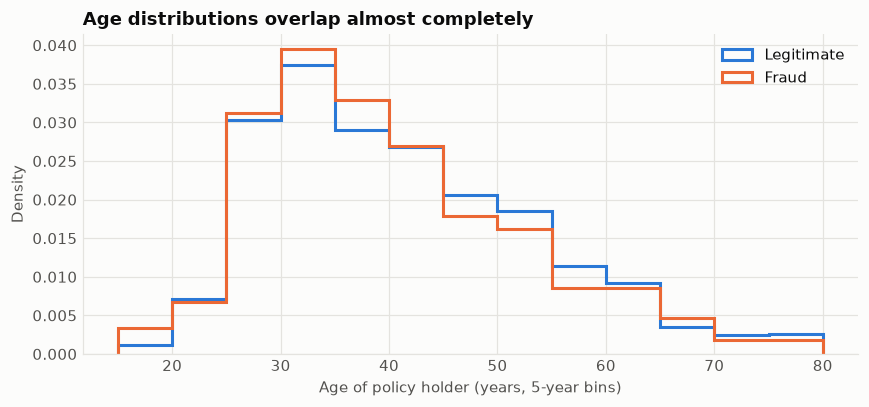

In [21]:
age = df.dropna(subset=["Age"])
bins = np.arange(15, 85, 5)
fig, ax = plt.subplots(figsize=(8, 3.8))
for label, value, color in [("Legitimate", 0, plotting.COLOR_LEGIT), ("Fraud", 1, plotting.COLOR_FRAUD)]:
    ax.hist(age.loc[age[config.TARGET] == value, "Age"], bins=bins, density=True,
            histtype="step", linewidth=2, color=color, label=label)
ax.set_xlabel("Age of policy holder (years, 5-year bins)")
ax.set_ylabel("Density")
ax.set_title("Age distributions overlap almost completely")
ax.legend()
fig.tight_layout()
plotting.save_fig(fig, "04_age_distribution")
plt.show()

Sahtekârlık taleplerinde ortalama yaş 39,6; meşru taleplerde 40,8. Fark iki testte de
anlamlı (p < 0,01) ama **Cohen's d ≈ −0,10**: pratikte ihmal edilebilir bir etki.
Büyük örneklemde p-değeri tek başına yeterli değil; etki büyüklüğü raporlanmalı.

## 8. Etkileşim: kusur × poliçe türü

İki güçlü değişken birlikte nasıl davranıyor?

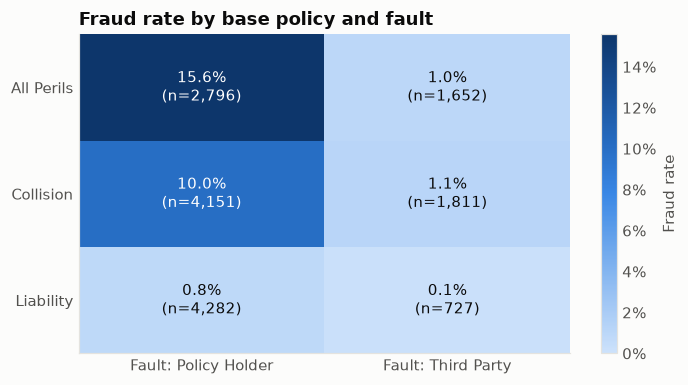

In [22]:
rate = df.pivot_table(index="BasePolicy", columns="Fault", values=config.TARGET, aggfunc="mean")
size = df.pivot_table(index="BasePolicy", columns="Fault", values=config.TARGET, aggfunc="size")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blues", plotting.SEQUENTIAL)
im = ax.imshow(rate.to_numpy(), cmap=cmap, vmin=0, vmax=rate.to_numpy().max(), aspect="auto")
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        value = rate.iat[i, j]
        ax.text(j, i, f"{value:.1%}\n(n={size.iat[i, j]:,})", ha="center", va="center",
                color="white" if value > 0.08 else plotting.INK, fontsize=10)
ax.set_xticks(range(rate.shape[1]), [f"Fault: {c}" for c in rate.columns])
ax.set_yticks(range(rate.shape[0]), rate.index)
ax.set_title("Fraud rate by base policy and fault")
ax.grid(False)
fig.colorbar(im, ax=ax, format=plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0),
             label="Fraud rate")
fig.tight_layout()
plotting.save_fig(fig, "05_fault_policy_heatmap")
plt.show()

In [23]:
segment = df[(df["Fault"] == "Policy Holder") & (df["BasePolicy"] != "Liability")]
print(f"Policy-holder fault + non-liability policy: {len(segment):,} claims "
      f"({len(segment) / len(df):.1%} of all), fraud rate {segment[config.TARGET].mean():.1%}, "
      f"contains {segment[config.TARGET].sum() / df[config.TARGET].sum():.1%} of all frauds")

Policy-holder fault + non-liability policy: 6,947 claims (45.1% of all), fraud rate 12.2%, contains 92.2% of all frauds


Poliçe sahibinin kusurlu olduğu "All Perils" taleplerinde oran **%15,6**; üçüncü tarafın
kusurlu olduğu sorumluluk taleplerinde **%0,1**. Yalnızca "kusur poliçe sahibinde ve poliçe
sorumluluk değil" kuralı, taleplerin %45'ini seçip sahtekârlıkların %92'sini kapsıyor.

Bu basit kural, modelin aşması gereken **gerçek temel çizgidir**: bir model ancak bu
segmentin *içinde* de sıralama yapabiliyorsa değer katar.

## 9. Özet

1. Veri temiz görünüyor ama gizli sorunlar var: `Age = 0`, tutarsız yaş bantları,
   satır numarası olan `PolicyNumber`, türetilmiş `PolicyType`.
2. Sahtekârlık oranı %6: accuracy kullanılamaz, PR-AUC ve precision/recall gerekir.
3. En güçlü sinyaller: kusur, poliçe türü, araç kategorisi, adres değişikliği, muafiyet.
   Etki büyüklükleri zayıf–orta; tek değişkenle çözülecek bir problem değil.
4. Büyük örneklem nedeniyle birçok değişken "anlamlı" ama etkisi ihmal edilebilir;
   bu yüzden her testte etki büyüklüğü ve çoklu test düzeltmesi raporlandı.
5. Tek değişkenli ilişkiler yanıltabilir: geçmiş hasar sayısının etkisi poliçe karışımıyla
   açıklanıyor; "muafiyet 500" ile "adres değişikliği 2–3 yıl" aynı talep kümesi.
6. İlişkilerin çoğu doğrusal değil ve etkileşim içeriyor: ağaç tabanlı bir modelin
   lojistik regresyona göre avantajlı olması beklenir. Sonraki defterde test edilir.